# Similarity structure of the recorded populations and of the fitted models

Sec. 2.3 shows that commuting skew-symmetric generators make the cosine similarity between two
population vectors a function of their displacement alone (Eq. 3),

$$C(\Delta x, \Delta y) = \frac{\mathbf{p}_0^T e^{\Delta x G_x + \Delta y G_y}\mathbf{p}_0}{\lVert\mathbf{p}_0\rVert^2}.$$

The fitted models of Sec. 3.2 / App. K have such generators, so **their similarity is translation
invariant by construction**. Plotting it from several reference points shows the same function
shifted, and is a check of the code, not a finding. What the recordings can test is the other
half:

1. *Does the model's similarity look like the data's?* The similarity between one reference
   point and every other point, for the data and for the model, at reference points inside the
   trained square and in the part of the arena not trained on.
2. *Is the data's similarity translation invariant?* That is, how much of
   $C_\text{data}(\mathbf{r}_0, \mathbf{r})$ is a function of $\mathbf{r} - \mathbf{r}_0$ alone.
3. *Does the similarity function carry over to the part not trained on?* The model saw only the
   central square. Its similarity function is compared with the data on pairs of points that
   involve the rest of the arena, next to the data's own similarity function measured inside
   the square.

The model is the extrapolation fit of notebooks 12 (grid cells) and 15 (place cells, one
animal): trained on the central three quarters of the arena side and generated over the whole
arena from its centre, so the part not trained on has ground truth. The full-arena fit is
scored in the table as well. Nothing is refitted here; the notebook reads the saved fits.

Similarity is the cosine similarity of the paper throughout. The data are not equinorm, so the
normalisation matters for them; for the model it is the constant $\lVert\mathbf{p}_0\rVert^2$.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import expm

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures" / "similarity"
FITS = {
    "grid": REPO_ROOT / "data" / "gc_fit_commuting.npz",
    "place": REPO_ROOT / "data" / "ca1_fit_one_animal_si0.50.npz",
}

# Reference pixels (x, y) for the similarity maps. The trained square is pixels 4..28, so the
# first three lie inside it and the last three in the part of the arena not trained on.
REFERENCES = [(16, 16), (9, 21), (22, 10), (1, 16), (16, 30), (29, 2)]
# Largest displacement per axis, in pixels, entering the scores. Up to half the arena side every
# displacement is averaged over at least 64 pairs inside the trained square, so no single
# reference point decides the similarity function it is compared against.
MAX_LAG = 16
N_ROLLS = 20  # realisations of the rolled-map control
N_CHECK = 200  # displacements at which Eq. 3 is evaluated from the saved generators
WEIGHT_SHOWN = 0.01  # wavevector pairs carrying more than this share of the similarity are listed
SEED = 0

# Rates are non-negative, so the data's cosine similarity never crosses zero (it stays above
# 0.47 for the grid cells). A sequential map over the occupied range shows the structure; a
# diverging map pinned at zero would spend half its range on values that do not occur.
CMAP = "magma"

plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["figure.dpi"] = 150
FIGURE_DIR.mkdir(exist_ok=True)


def save(fig, stem):
    fig.savefig(FIGURE_DIR / f"{stem}.png", dpi=200, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{stem}.svg", bbox_inches="tight")

## Similarity, its displacement kernel, and the scores

`C[i, j, k, l]` is the cosine similarity between the population vectors at pixels $(i, j)$ and
$(k, l)$. Its *displacement kernel* is the average of `C` over all pairs with the same
displacement; a translation-invariant similarity equals its kernel, and the kernel is the best
translation-invariant description of one that is not. Agreement between a similarity and a
prediction of it is scored over pairs of pixels by the correlation and by the fraction of
variance explained, $1 - \langle (C - \hat C)^2\rangle / \mathrm{var}(C)$, which unlike the
correlation also penalises an offset.

In [2]:
def cosine_similarity(maps):
    """Cosine similarity between the population vectors at every pair of pixels (Sec. 2.3).

    `maps` is indexed (unit, bins_x, bins_y); `C[i, j, k, l]` compares pixel (i, j) with (k, l).
    """
    n = maps.shape[1]
    p = maps.reshape(len(maps), -1).T.astype(np.float64)
    p /= np.linalg.norm(p, axis=1, keepdims=True)
    return (p @ p.T).reshape(n, n, n, n)


def displacement_kernel(C, pairs):
    """Average of `C` over the pixel pairs in `pairs` that share a displacement.

    Returns the kernel indexed by displacement, `kernel[dx + n - 1, dy + n - 1]`, NaN where no
    pair has that displacement, and the number of pairs behind each entry.
    """
    n = C.shape[0]
    total, count = np.zeros((2 * n - 1, 2 * n - 1)), np.zeros((2 * n - 1, 2 * n - 1))
    for i in range(n):
        for j in range(n):
            window = (slice(n - 1 - i, 2 * n - 1 - i), slice(n - 1 - j, 2 * n - 1 - j))
            total[window] += np.where(pairs[i, j], C[i, j], 0)
            count[window] += pairs[i, j]
    return total / np.where(count > 0, count, np.nan), count


def from_kernel(kernel, n):
    """The translation-invariant similarity with this kernel, `C[i, j, k, l] = kernel(k - i, l - j)`."""
    C = np.empty((n, n, n, n))
    for i in range(n):
        for j in range(n):
            C[i, j] = kernel[n - 1 - i : 2 * n - 1 - i, n - 1 - j : 2 * n - 1 - j]
    return C


def pair_classes(inner, max_lag):
    """Pixel pairs by where their two points lie relative to the trained square `inner`.

    Returns the pairs within `max_lag` pixels per axis (a pixel paired with itself excluded) and,
    among all pairs, the three classes: both points inside, one inside, both outside.
    """
    n = len(inner)
    lag = np.abs(np.arange(n)[:, None] - np.arange(n)[None, :])
    near = (lag <= max_lag)[:, None, :, None] & (lag <= max_lag)[None, :, None, :]
    near &= ~((lag == 0)[:, None, :, None] & (lag == 0)[None, :, None, :])
    a, b = inner[:, :, None, None], inner[None, None, :, :]
    return near, {"both inside": a & b, "one inside, one outside": a ^ b, "both outside": ~a & ~b}


def agreement(C, prediction, pairs):
    """Correlation and fraction of variance of `C` explained by `prediction` over the pairs in `pairs`."""
    c, q = C[pairs], prediction[pairs]
    return np.corrcoef(c, q)[0, 1], 1 - ((c - q) ** 2).mean() / c.var()

## The saved fits

Per dataset: the data, the extrapolation fit's maps over the whole arena with its generators,
the full-arena fit's maps with its mixing matrix and wavevectors, and the trained square. Then the similarities and the kernels: the
model's, and the data's measured separately on pairs with both points inside the trained
square and on pairs with a point outside it.

In [3]:
def load(path):
    d = np.load(path)
    inner = d["inner"]
    lo = int(np.argmax(inner[len(inner) // 2]))
    return {
        "data": d["experimental"],
        "model": d["extrapolated"],
        "model_full": d["generated"],
        "Gx": d["crop_Gx"].astype(np.float64),
        "Gy": d["crop_Gy"].astype(np.float64),
        # R and the wavevectors are saved for the full-arena fit only
        "R": d["R"].astype(np.float64),
        "wavevectors": d["wavevectors"].astype(np.float64),
        "inner": inner,
        "box": (lo, len(inner) - lo),
    }


fits = {name: load(path) for name, path in FITS.items()}
for name, f in fits.items():
    n = f["data"].shape[1]
    f["C_data"], f["C_model"], f["C_model_full"] = (cosine_similarity(f[k]) for k in ("data", "model", "model_full"))
    f["near"], f["classes"] = pair_classes(f["inner"], MAX_LAG)
    inside = f["classes"]["both inside"]
    f["kernel_model"], _ = displacement_kernel(f["C_model"], np.ones_like(inside))
    f["kernel_inside"], count = displacement_kernel(f["C_data"], inside)
    f["kernel_outside"], _ = displacement_kernel(f["C_data"], ~inside)
    f["C_kernel"] = from_kernel(f["kernel_inside"], n)
    window = slice(n - 1 - MAX_LAG, n + MAX_LAG)
    print(
        f"{name}: {len(f['data'])} units, trained square pixels {f['box'][0]}..{f['box'][1]}; "
        f"data similarity {f['C_data'].min():.2f}..1, model {f['C_model'].min():.2f}..1; "
        f"pairs per displacement behind the in-square kernel: at least {int(count[window, window].min())}"
    )

grid: 102 units, trained square pixels 4..28; data similarity 0.48..1, model 0.71..1; pairs per displacement behind the in-square kernel: at least 64
place: 103 units, trained square pixels 4..28; data similarity 0.02..1, model -0.36..1; pairs per displacement behind the in-square kernel: at least 64


## Checks: what holds by construction

The model's population norm is constant over the arena and its similarity is a function of
displacement alone: it equals its own displacement kernel, and the kernel equals Eq. 3
evaluated from the saved generators at randomly drawn displacements. The data's norm is not
constant, which is the equinorm property the model imposes and the recordings do not have.

In [4]:
rng = np.random.default_rng(SEED)
for name, f in fits.items():
    n = f["data"].shape[1]
    norms = {k: np.linalg.norm(f[k].reshape(len(f[k]), -1), axis=0) for k in ("data", "model")}
    invariance_gap = np.abs(f["C_model"] - from_kernel(f["kernel_model"], n)).max()

    p0 = f["model"][:, n // 2, n // 2].astype(np.float64)
    steps = rng.integers(-(n - 1), n, size=(N_CHECK, 2))
    eq3 = np.array([p0 @ expm((2 / n) * (dx * f["Gx"] + dy * f["Gy"])) @ p0 for dx, dy in steps]) / (p0 @ p0)
    eq3_gap = np.abs(eq3 - f["kernel_model"][steps[:, 0] + n - 1, steps[:, 1] + n - 1]).max()

    print(
        f"{name}: ||p|| std/mean over the arena, data {norms['data'].std() / norms['data'].mean():.2f}, "
        f"model {norms['model'].std() / norms['model'].mean():.0e}; "
        f"model similarity vs its kernel max |diff| {invariance_gap:.0e}; "
        f"kernel vs Eq. 3 at {N_CHECK} displacements max |diff| {eq3_gap:.0e}"
    )
    assert invariance_gap < 1e-5 and eq3_gap < 1e-5

grid: ||p|| std/mean over the arena, data 0.18, model 1e-07; model similarity vs its kernel max |diff| 5e-07; kernel vs Eq. 3 at 200 displacements max |diff| 1e-06
place: ||p|| std/mean over the arena, data 0.21, model 3e-07; model similarity vs its kernel max |diff| 1e-06; kernel vs Eq. 3 at 200 displacements max |diff| 2e-06


## Similarity from one point to all others

Data above, model below, one column per reference point (red cross), in arena coordinates.
The white square is the trained part. The first three reference points lie inside it, the
last three in the part not trained on. Each dataset has one colour scale for all its panels.
The number is the correlation between the data's and the model's map for that reference
point, over all other pixels.

The model row is one function shifted to each reference point, as it must be. The question is
whether the data row does the same, and whether the two rows agree.

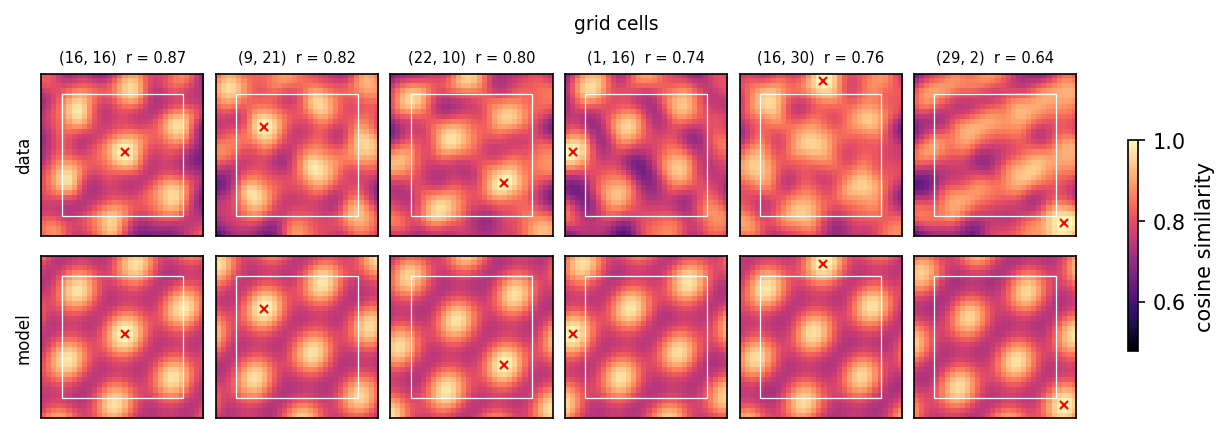

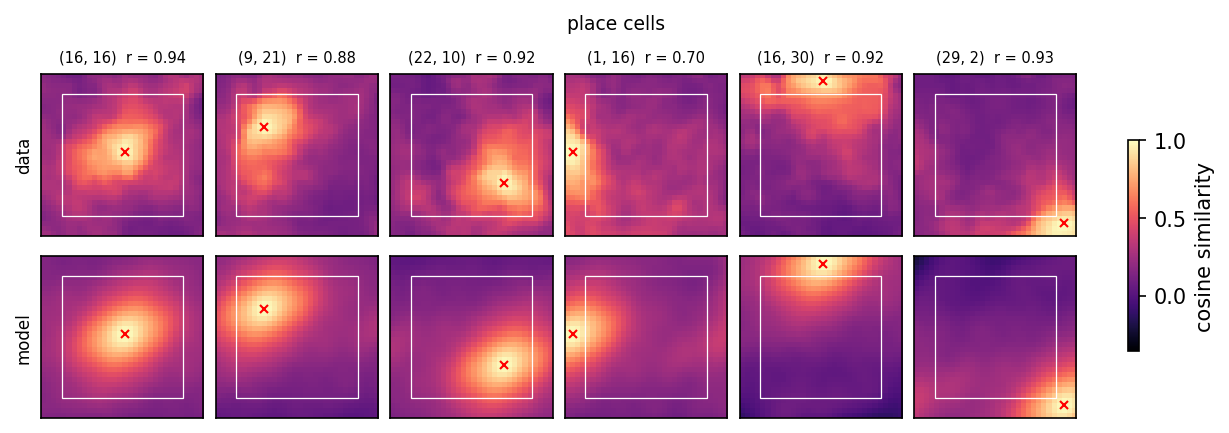

In [5]:
def similarity_maps(f, references):
    n = f["data"].shape[1]
    lo, hi = f["box"]
    vmin = min(f["C_data"].min(), f["C_model"].min())
    fig, axs = plt.subplots(2, len(references), figsize=(1.2 * len(references) + 0.9, 2.8), layout="constrained")
    for col, (i, j) in enumerate(references):
        for ax, C in zip(axs[:, col], (f["C_data"], f["C_model"])):
            image = ax.imshow(C[i, j].T, origin="lower", cmap=CMAP, vmin=vmin, vmax=1)
            ax.add_patch(
                plt.Rectangle((lo - 0.5, lo - 0.5), hi - lo, hi - lo, fill=False, edgecolor="w", linewidth=0.6)
            )
            ax.plot(i, j, "x", color="r", markersize=4)
            ax.set_xticks([])
            ax.set_yticks([])
        others = np.ones((n, n), bool)
        others[i, j] = False
        r = np.corrcoef(f["C_data"][i, j][others], f["C_model"][i, j][others])[0, 1]
        axs[0, col].set_title(f"({i}, {j})  r = {r:.2f}", fontsize=7)
    axs[0, 0].set_ylabel("data", fontsize=8)
    axs[1, 0].set_ylabel("model", fontsize=8)
    fig.colorbar(image, ax=axs, shrink=0.6, label="cosine similarity")
    return fig


for name, f in fits.items():
    fig = similarity_maps(f, REFERENCES)
    fig.suptitle(f"{name} cells", fontsize=9)
    save(fig, f"{name}_similarity_from_reference_points")

## Translation invariance of the data

Left three panels: the similarity as a function of displacement. The data's kernel from pairs
with both points inside the trained square, the data's kernel from pairs with a point outside
it, and the model's similarity function, which was learned from the square alone.

Right panel: the similarity between two points displaced by $(\Delta x, 0)$, over every such
pair in the arena. For a translation-invariant similarity all pairs with the same displacement
give the same value. The bands are the 10th to 90th percentile over pairs, the lines the
medians; the model is a single curve with no spread.

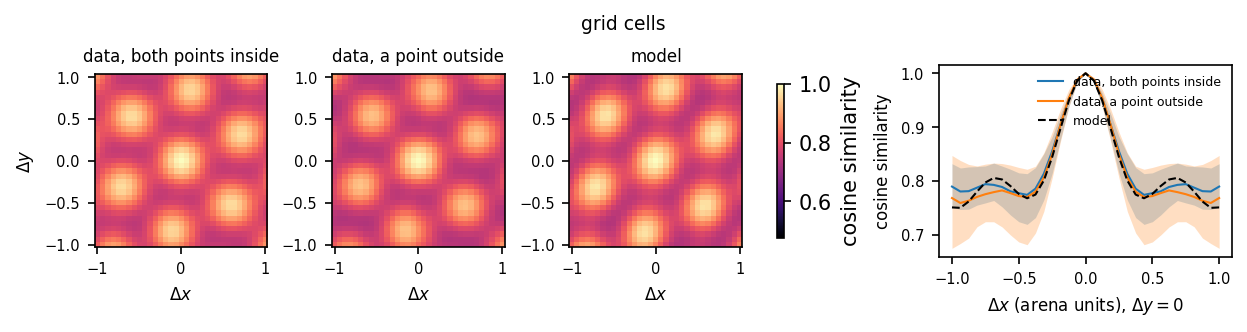

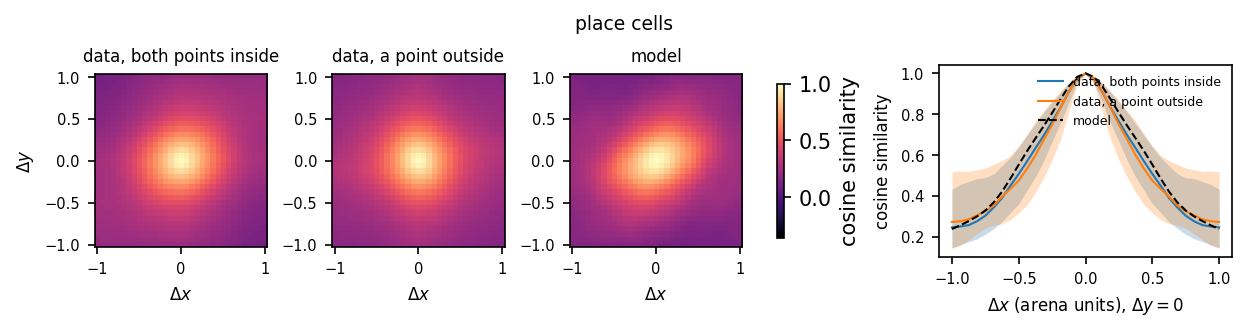

In [6]:
def cut_along_x(C, pairs, lags):
    """10th, 50th and 90th percentile of `C` over the pairs in `pairs` displaced by (dx, 0), per dx in `lags`."""
    n = C.shape[0]
    # [i, k, j]: pixel (i, j) against pixel (k, j)
    Cx, px = np.diagonal(C, axis1=1, axis2=3), np.diagonal(pairs, axis1=1, axis2=3)
    out = []
    for dx in lags:
        i = np.arange(max(0, -dx), min(n, n - dx))
        out.append(np.percentile(Cx[i, i + dx][px[i, i + dx]], [10, 50, 90]))
    return np.array(out).T


def kernel_figure(f):
    n = f["data"].shape[1]
    vmin = min(f["C_data"].min(), f["C_model"].min())
    window = slice(n - 1 - MAX_LAG, n + MAX_LAG)
    extent = np.array([-1, 1, -1, 1]) * (MAX_LAG + 0.5) * 2 / n
    lags = np.arange(-MAX_LAG, MAX_LAG + 1)
    inside = f["classes"]["both inside"]

    fig, axs = plt.subplots(1, 4, figsize=(8.2, 2.1), layout="constrained", width_ratios=[1, 1, 1, 1.7])
    kernels = {
        "data, both points inside": f["kernel_inside"],
        "data, a point outside": f["kernel_outside"],
        "model": f["kernel_model"],
    }
    for ax, (title, kernel) in zip(axs, kernels.items()):
        image = ax.imshow(kernel[window, window].T, origin="lower", cmap=CMAP, vmin=vmin, vmax=1, extent=extent)
        ax.set_title(title, fontsize=8)
        ax.set_xlabel(r"$\Delta x$", fontsize=8)
        ax.tick_params(labelsize=7)
    axs[0].set_ylabel(r"$\Delta y$", fontsize=8)
    fig.colorbar(image, ax=axs[:3], shrink=0.8, label="cosine similarity")

    ax = axs[3]
    for label, pairs, color in [("data, both points inside", inside, "C0"), ("data, a point outside", ~inside, "C1")]:
        low, median, high = cut_along_x(f["C_data"], pairs, lags)
        ax.fill_between(lags * 2 / n, low, high, color=color, alpha=0.25, linewidth=0)
        ax.plot(lags * 2 / n, median, color=color, linewidth=1, label=label)
    ax.plot(lags * 2 / n, f["kernel_model"][lags + n - 1, n - 1], "k--", linewidth=1, label="model")
    ax.set_xlabel(r"$\Delta x$ (arena units), $\Delta y = 0$", fontsize=8)
    ax.set_ylabel("cosine similarity", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.legend(frameon=False, fontsize=6, loc="upper right")
    return fig


for name, f in fits.items():
    fig = kernel_figure(f)
    fig.suptitle(f"{name} cells", fontsize=9)
    save(fig, f"{name}_similarity_kernels")

## Scores

Each row scores one description of the data's similarity, over pairs of pixels up to `MAX_LAG`
apart per axis, split by where the two points lie. Correlation first, fraction of variance
explained second.

- **model, trained on the square**: the extrapolation fit. Pairs with a point outside the
  square are out of sample for it.
- **model, trained on the arena**: the full-arena fit, for reference. Nothing is out of sample.
- **data's kernel from the square**: the data's own similarity function, measured on pairs
  inside the trained square and applied everywhere. Inside the square this is how translation
  invariant the data are; outside it, how well the similarity structure of the square carries
  over to the rest of the arena. No translation-invariant model given the same data can be
  expected to do better.
- **rolled control**: the same score as the row above for a surrogate population in which
  every unit's map is shifted by an independent random offset, wrapping around the arena
  (mean ± std over `N_ROLLS` draws). The surrogate has no preferred location, so its
  similarity is translation invariant up to what a finite number of units with these tuning
  curves allows, and it calibrates the numbers. It is a rough reference: the wrap-around cuts
  fields and lattices at the walls.

In [7]:
rng = np.random.default_rng(SEED)
for name, f in fits.items():
    n = f["data"].shape[1]
    inside = f["classes"]["both inside"]

    rolled_scores = {label: [] for label in f["classes"]}
    for _ in range(N_ROLLS):
        rolled = np.stack([np.roll(unit, rng.integers(0, n, size=2), axis=(0, 1)) for unit in f["data"]])
        C_rolled = cosine_similarity(rolled)
        C_rolled_kernel = from_kernel(displacement_kernel(C_rolled, inside)[0], n)
        for label, pairs in f["classes"].items():
            rolled_scores[label].append(agreement(C_rolled, C_rolled_kernel, f["near"] & pairs))

    rows = {
        "model, trained on the square": f["C_model"],
        "model, trained on the arena": f["C_model_full"],
        "data's kernel from the square": f["C_kernel"],
    }
    print(
        f"{name} cells, correlation / variance explained".ljust(46) + "".join(f"{label:>26s}" for label in f["classes"])
    )
    for row, prediction in rows.items():
        scores = [agreement(f["C_data"], prediction, f["near"] & pairs) for pairs in f["classes"].values()]
        print(f"  {row:44s}" + "".join(f"{f'{r:.2f} / {ev:.2f}':>26s}" for r, ev in scores))
    cells = [np.array(rolled_scores[label]) for label in f["classes"]]
    print(
        f"  {'rolled control, its own kernel':44s}"
        + "".join(f"{f'{s[:, 0].mean():.2f} / {s[:, 1].mean():.2f} ± {s[:, 1].std():.2f}':>26s}" for s in cells)
    )
    r, ev = agreement(f["kernel_inside"], f["kernel_model"], np.isfinite(f["kernel_inside"]))
    print(
        f"  model's similarity function against the data's kernel from the square: correlation {r:.2f}, explained {ev:.2f}\n"
    )

grid cells, correlation / variance explained                 both inside   one inside, one outside              both outside
  model, trained on the square                               0.88 / 0.75               0.72 / 0.47               0.77 / 0.55
  model, trained on the arena                                0.86 / 0.65               0.70 / 0.43               0.76 / 0.55
  data's kernel from the square                              0.89 / 0.80               0.73 / 0.48               0.78 / 0.55
  rolled control, its own kernel                      0.84 / 0.71 ± 0.03        0.76 / 0.57 ± 0.03        0.88 / 0.76 ± 0.04
  model's similarity function against the data's kernel from the square: correlation 0.95, explained 0.85



place cells, correlation / variance explained                both inside   one inside, one outside              both outside
  model, trained on the square                               0.92 / 0.82               0.82 / 0.62               0.88 / 0.71
  model, trained on the arena                                0.92 / 0.83               0.82 / 0.63               0.88 / 0.72
  data's kernel from the square                              0.93 / 0.86               0.84 / 0.70               0.89 / 0.77
  rolled control, its own kernel                      0.91 / 0.83 ± 0.03        0.84 / 0.70 ± 0.03        0.92 / 0.83 ± 0.05
  model's similarity function against the data's kernel from the square: correlation 0.97, explained 0.86



## Where in the arena the agreement holds

For every reference pixel, the correlation between the data's similarity map from that pixel
and (left) the model's, (right) the data's own kernel from the trained square, over the other
pixels within `MAX_LAG` per axis. The white square is the trained part.

grid, data vs model: median correlation over reference pixels 0.85 inside the square, 0.81 outside
grid, data vs data's kernel: median correlation over reference pixels 0.86 inside the square, 0.83 outside
place, data vs model: median correlation over reference pixels 0.91 inside the square, 0.88 outside
place, data vs data's kernel: median correlation over reference pixels 0.93 inside the square, 0.90 outside


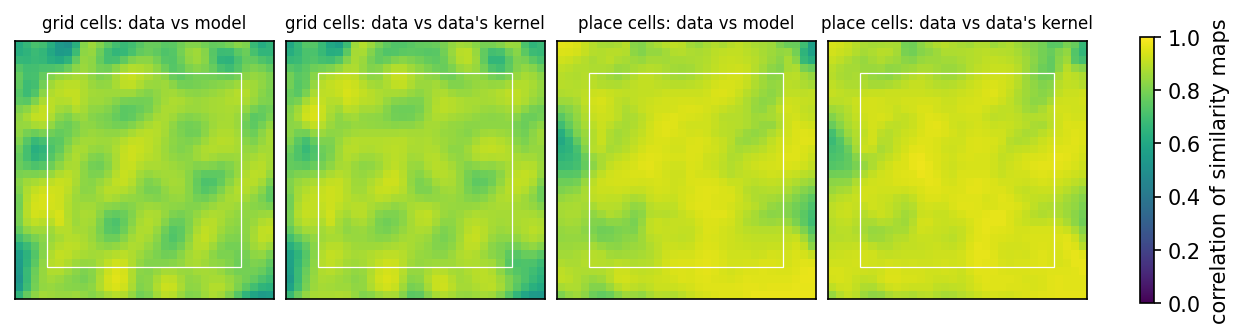

In [8]:
def per_reference_correlation(C, prediction, pairs):
    """Correlation between `C` and `prediction` over the pixels paired with each reference pixel, shape (n, n)."""
    n = C.shape[0]
    r = np.empty((n, n))
    for i in range(n):
        for j in range(n):
            r[i, j] = np.corrcoef(C[i, j][pairs[i, j]], prediction[i, j][pairs[i, j]])[0, 1]
    return r


fig, axs = plt.subplots(1, 4, figsize=(8.2, 2.3), layout="constrained")
for k, (name, f) in enumerate(fits.items()):
    lo, hi = f["box"]
    for ax, (title, prediction) in zip(axs[2 * k :], [("model", f["C_model"]), ("data's kernel", f["C_kernel"])]):
        r = per_reference_correlation(f["C_data"], prediction, f["near"])
        image = ax.imshow(r.T, origin="lower", cmap="viridis", vmin=0, vmax=1)
        ax.add_patch(plt.Rectangle((lo - 0.5, lo - 0.5), hi - lo, hi - lo, fill=False, edgecolor="w", linewidth=0.6))
        ax.set_title(f"{name} cells: data vs {title}", fontsize=8)
        ax.set_xticks([])
        ax.set_yticks([])
        print(
            f"{name}, data vs {title}: median correlation over reference pixels "
            f"{np.median(r[f['inner']]):.2f} inside the square, {np.median(r[~f['inner']]):.2f} outside"
        )
fig.colorbar(image, ax=axs, shrink=0.8, label="correlation of similarity maps")
save(fig, "similarity_agreement_by_reference")

## Which wavevectors carry the similarity

Block-diagonalising the generators turns Eq. 3 into a sum of cosines (Eq. 4),

$$C(\Delta x, \Delta y) = \sum_i \alpha_{0,i}^2 \cos(\lambda_{i,x}\Delta x + \lambda_{i,y}\Delta y),
\qquad \boldsymbol{\alpha}_0 = R\,\mathbf{p}_0 / \lVert\mathbf{p}_0\rVert,$$

so the weight of a fitted wavevector pair, the sum of its two $\alpha_{0,i}^2$, is its share of
the similarity function. Transport rotates each pair without changing its length, so the weights
are the same at every position; they are a property of the fitted population, not of the pixel
they are read from. This uses the full-arena fit, the one whose $R$ and wavevectors are saved.
Eq. 4 with these weights is checked against that model's similarity first. With an odd number
of units one direction does not transport and adds a constant.

In the figure every fitted pair is a grey dot at $\pm\boldsymbol{\lambda}$, in cycles per arena
side, and the black discs have areas proportional to the weights.

grid: Eq. 4 vs the model's similarity max |diff| 3e-07; static direction 0.0000; 7 of 51 pairs above 1%, together 0.96
  weight  cycles per arena  orientation (deg)
   0.751              0.05                 34
   0.064              2.69                112
   0.039              2.73                 47
   0.038              2.92                170
   0.033              0.15                 75
   0.019              2.92                170
   0.019              0.31                140
place: Eq. 4 vs the model's similarity max |diff| 9e-07; static direction 0.0002; 21 of 51 pairs above 1%, together 0.90
  weight  cycles per arena  orientation (deg)
   0.225              0.19                145
   0.105              0.43                 64
   0.085              0.80                101
   0.081              1.03                137
   0.038              0.79                  4
   0.036              0.76                 44
   0.033              1.73                134
   0.033              0.

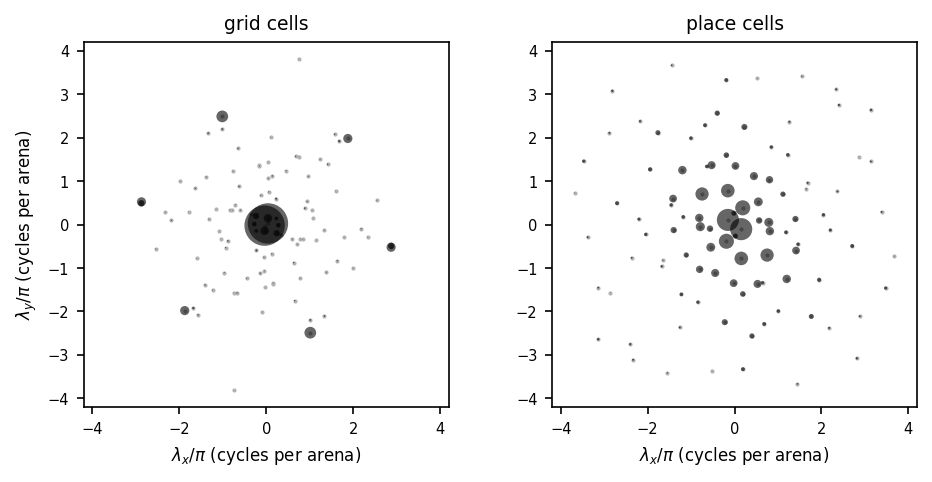

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 3.1), layout="constrained")
for ax, (name, f) in zip(axs, fits.items()):
    n = f["data"].shape[1]
    lam, n_paired = f["wavevectors"], 2 * len(f["wavevectors"])
    p0 = f["model_full"][:, n // 2, n // 2].astype(np.float64)
    alpha0 = f["R"] @ p0 / np.linalg.norm(p0)
    weight = alpha0[0:n_paired:2] ** 2 + alpha0[1:n_paired:2] ** 2
    static = (alpha0[n_paired:] ** 2).sum()

    steps = np.stack(np.meshgrid(np.arange(n) - n // 2, np.arange(n) - n // 2, indexing="ij"), axis=-1)
    eq4 = np.cos((2 / n) * steps @ lam.T) @ weight + static
    eq4_gap = np.abs(eq4 - f["C_model_full"][n // 2, n // 2]).max()
    assert eq4_gap < 1e-5

    cycles = np.hypot(lam[:, 0], lam[:, 1]) / np.pi
    orientation = np.degrees(np.arctan2(lam[:, 1], lam[:, 0])) % 180
    order = np.argsort(-weight)
    shown = order[weight[order] > WEIGHT_SHOWN]
    print(
        f"{name}: Eq. 4 vs the model's similarity max |diff| {eq4_gap:.0e}; static direction {static:.4f}; "
        f"{len(shown)} of {len(weight)} pairs above {WEIGHT_SHOWN:.0%}, together {weight[shown].sum():.2f}"
    )
    print("  weight  cycles per arena  orientation (deg)")
    for k in shown:
        print(f"  {weight[k]:6.3f}  {cycles[k]:16.2f}  {orientation[k]:17.0f}")

    both = np.concatenate([lam, -lam]) / np.pi  # each pair is a +/- wavevector
    ax.scatter(both[:, 0], both[:, 1], s=4, color="0.7", linewidth=0)
    ax.scatter(both[:, 0], both[:, 1], s=500 * np.tile(weight, 2), color="k", alpha=0.6, linewidth=0)
    ax.set_aspect("equal")
    ax.set_xlim(-4.2, 4.2)
    ax.set_ylim(-4.2, 4.2)
    ax.set_title(f"{name} cells", fontsize=9)
    ax.set_xlabel(r"$\lambda_x / \pi$ (cycles per arena)", fontsize=8)
    ax.tick_params(labelsize=7)
axs[0].set_ylabel(r"$\lambda_y / \pi$ (cycles per arena)", fontsize=8)
save(fig, "similarity_weights_by_wavevector")

## Reading

Numbers from the saved fits as of 2026-11-05 (seed 0).

- **The model's similarity function matches the data's.** It correlates at 0.95 (grid cells)
  and 0.97 (place cells) with the data's kernel measured in the trained square. Scored against
  the data's pairwise similarity it comes close to that kernel in every column of the table,
  including the pairs that involve the part of the arena not trained on. The kernel is the
  ceiling for a translation-invariant description, so most of what the model misses is the
  data's own departure from translation invariance.
- **Inside the trained square the recorded populations are about as translation invariant as
  the rolled control.** The data's kernel explains 0.80 (grid) and 0.86 (place) of the variance
  of the similarity there, against 0.71 ± 0.03 and 0.83 ± 0.03 for the control.
- **Towards the walls the grid-cell similarity departs from it.** On pairs with both points
  outside the square the kernel explains 0.55 for the grid cells against 0.76 ± 0.04 for the
  control, and the last figure places the low values at the walls and corners. For the place
  cells the same comparison is 0.77 against 0.83 ± 0.05.
- **The grid fit's similarity is carried by one hexagonal set of wavevectors.** Three quarters
  of the weight (0.75) sits on a nearly constant component, as expected for non-negative rates
  that are not sparse. Of the rest, 0.16 sits on four pairs at 2.7 to 2.9 cycles per arena with
  orientations 47°, 112° and 170° (twice), about 60° apart, as for one grid module. The place
  fit spreads its weight over many pairs below 3 cycles per arena (21 above 1 %), with no
  preferred scale or orientation.
- **What is not a finding.** The model row of the similarity maps is one function shifted to
  each reference point because the generators are skew-symmetric and commute. Only the data
  rows and the data-against-model comparison carry information.

Qualifications. The place-cell population is pooled over 37 sessions of one rat, so its
population vectors were never observed simultaneously. The rate maps are smoothed, which by
itself makes neighbouring pixels similar in the same way everywhere and favours translation
invariance at displacements of a pixel or two. The rolled control cuts fields and lattices
where they wrap around the arena, so it is a rough reference. Everything is one fit per
dataset at one seed.